# Week 15 — Original Transolver on the double-step family

Same post-audit split: 100 training, 8 validation, 19 retrospective test cases; g005 quarantined. Three seeds, 19,200 updates each. Checkpoints selected on validation only. Weights and all test fields are committed with this notebook. This is not an equal-FLOP or equal-tuning ranking.

[Compact comparison and results](../../results/family_transolver/README.md)

In [1]:
# Late-course checkout setup
from pathlib import Path
import sys, os, subprocess, importlib.util
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / 'results/family_transolver/comparison.csv').exists()), None)
try:
    _in_colab = importlib.util.find_spec("google.colab") is not None
except (ModuleNotFoundError, ValueError):
    _in_colab = False
if _in_colab:
    _course_target = ROOT if ROOT is not None else Path("/content/FlowMLLab")
    if not _course_target.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none",
                        "--sparse", "https://github.com/Ehsan-Roohi/FlowMLLab.git",
                        str(_course_target)], check=True)
    _course_complete = all((_course_target / p).exists() for p in ['results/family_transolver/comparison.csv', 'flowmllab', 'qa', 'notebooks/week15', 'results/family_transolver', 'flowmllab/late_teaching_plots.py'])
    if not _course_complete and (_course_target / ".git").exists():
        _sparse = subprocess.run(["git", "-C", str(_course_target), "config", "--bool",
                                  "core.sparseCheckout"], capture_output=True, text=True, check=False)
        if _sparse.stdout.strip() != "true":
            raise RuntimeError("This full checkout is missing required lesson files; use a complete course checkout or a new Colab runtime.")
        # Add this lesson's dependencies; keep any previous sparse selection.
        subprocess.run(["git", "-C", str(_course_target), "sparse-checkout",
                        "add", *['flowmllab', 'qa', 'notebooks/week15', 'results/family_transolver']], check=True)
    elif not _course_complete:
        raise RuntimeError("The extracted course folder is incomplete for this lesson. Use the complete portable bundle or a new Colab runtime.")
    ROOT = _course_target
if ROOT is None or not all((ROOT / p).exists() for p in ['results/family_transolver/comparison.csv', 'flowmllab', 'qa', 'notebooks/week15', 'results/family_transolver', 'flowmllab/late_teaching_plots.py']):
    raise RuntimeError("Open this notebook in a FlowMLLab checkout, or use its Open in Colab link and run this setup cell first.")
ROOT = ROOT.resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Course checkout:", ROOT)

os.chdir(ROOT)

from pathlib import Path
import os, sys, subprocess
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'qa/train_family_transolver.py').exists())
os.chdir(ROOT)
print(ROOT)

Course checkout: /scratch3/workspace/roohie_umass_edu-flowml-ghia-highre-20261115/course-late-lectures-20261121/cpu-repo
/scratch3/workspace/roohie_umass_edu-flowml-ghia-highre-20261115/course-late-lectures-20261121/cpu-repo


In [2]:
RUN_TRAINING = False
if RUN_TRAINING:
    raise RuntimeError("This notebook is a retained-evidence lab. Campaign training must use an isolated output workspace; do not overwrite results/family_transolver.")
print("Default route: current saved-field identity checks and physical diagnostics; no training.")


Default route: current saved-field identity checks and physical diagnostics; no training.


In [3]:
import json
from IPython.display import display
retained_verification=json.loads((ROOT/"results/family_transolver/verification.json").read_text())
print("Historical replay:",retained_verification["checks"])
print("Current displayed-field hashes are checked in the physical comparison below; full replay is not run here.")


Historical replay: source/checkpoint hashes, frozen split, exact 57-field inference reproduction
Current displayed-field hashes are checked in the physical comparison below; full replay is not run here.


In [4]:
import pandas as pd
r=pd.read_csv('results/family_transolver/comparison.csv')
display(r[r['case'].str.contains('g049_Re100')][['seed','velocity_percent','pressure_percent','reverse_iou_u_lt_minus_001']])
display(r.groupby('seed')[['velocity_percent','pressure_percent','reverse_iou_u_lt_minus_001']].mean())

,seed,velocity_percent,pressure_percent,reverse_iou_u_lt_minus_001
14,17,21.503010,390.646881,0.650102
33,29,41.463425,478.762024,0.307839
52,43,16.425074,124.434753,0.504425


,velocity_percent,pressure_percent,reverse_iou_u_lt_minus_001
seed,,,
17,14.426055,210.427863,0.418597
29,35.817555,528.791075,0.239483
43,16.389551,92.177923,0.405624


## Aim and model input

Learn to evaluate a geometry-conditioned field operator on a **whole withheld geometry**, while separating checkpoint replay, training and physical assessment. The original Transolver receives spatial coordinates together with geometry/flow features and groups query information through learned physical-state attention. Changing the query set can affect that representation; it is not the same pointwise branch-trunk contraction introduced in the main notebook.

The retained double-step split has 100 training, 8 validation and 19 retrospectively inspected test cases. Validation selected checkpoints; the plots below do not select them again. The same 19,200-update cap does not equalize training FLOPs or all tuning choices across architecture families.

## Same-case comparison

<img src="../../results/family_transolver/all_models_g049_Re100.png" width="760" alt="Double-step g049 comparison including original Transolver">

Error labels use seed 17. Reverse IoU: u < -0.01, four-connected components, minimum eight cells. No test-derived model selection. The three-seed fields and Re=25/50/100 plots are in the results directory.

## Native fields, signs and seed variation

Aim: find where a prediction changes the separated flow, rather than treating a global error as a complete description. The controls below select one **previously inspected retained case**, one physical component and the same three training seeds. They neither select a new checkpoint nor retrain a model.

The first plot fills the CFD field and overlays each seed's prediction at the same physical contour levels. Its companion shows prediction minus CFD with a shared linear signed scale. The second figure compares a native downstream row, with solids masked. Pressure is centered over the same fluid cells for every field before comparison; this removes only the arbitrary constant gauge. A negative streamwise velocity indicates reverse flow, not by itself a complete vortex.

Choose the case before judging the errors. Repeat at Re=25, 50 and 100 where that same geometry exists; preserve all three seeds and report both a gain and a failure.

Retained cases: ['g012_Re25_medium', 'g012_Re50_medium', 'g045_Re100_medium', 'g045_Re25_medium', 'g045_Re50_medium', 'g046_Re100_medium', 'g046_Re25_medium', 'g046_Re50_medium', 'g047_Re100_medium', 'g047_Re25_medium', 'g047_Re50_medium', 'g048_Re100_medium', 'g048_Re25_medium', 'g048_Re50_medium', 'g049_Re100_medium', 'g049_Re25_medium', 'g049_Re50_medium', 'g050_Re25_medium', 'g051_Re25_medium']


,method,relative_l2,signed_error_min,signed_error_max
0,Transolver seed 17,0.214453,-0.214760,0.441206
1,Transolver seed 29,0.413085,-0.372489,1.100489
2,Transolver seed 43,0.163249,-0.253307,0.608337


Native profile row: 0.125 ; no checkpoint replay in this cell.


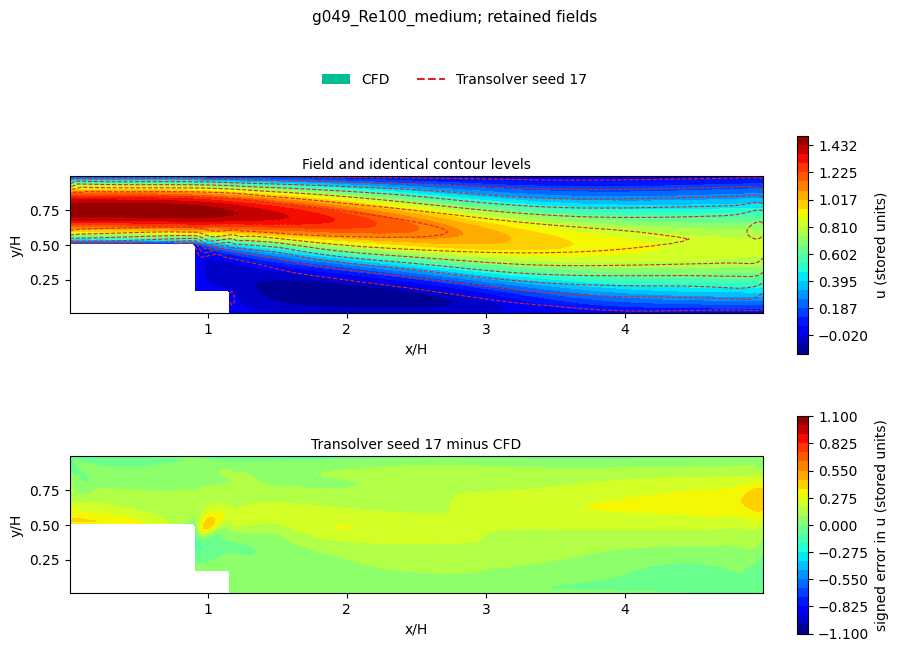

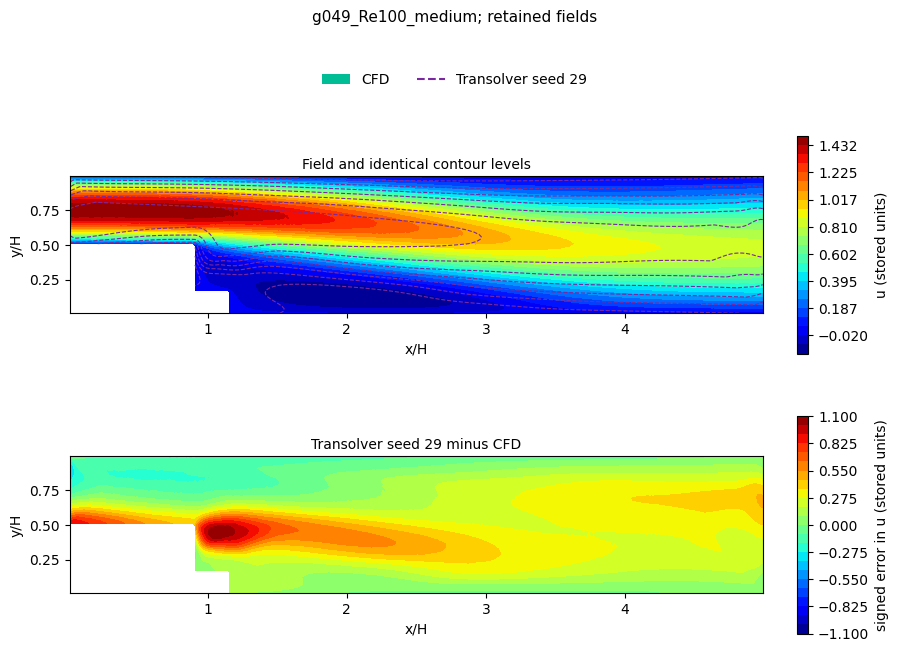

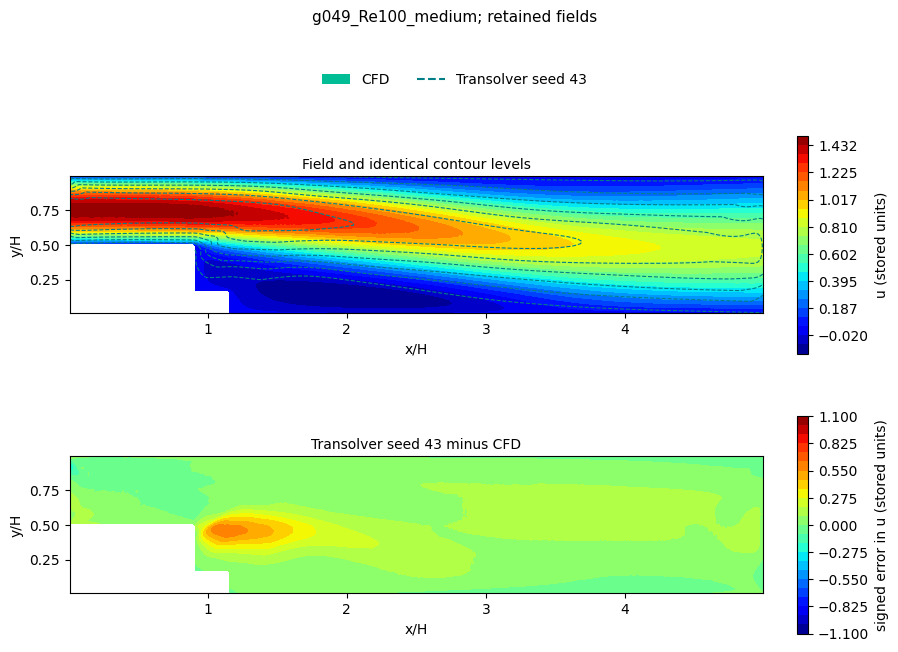

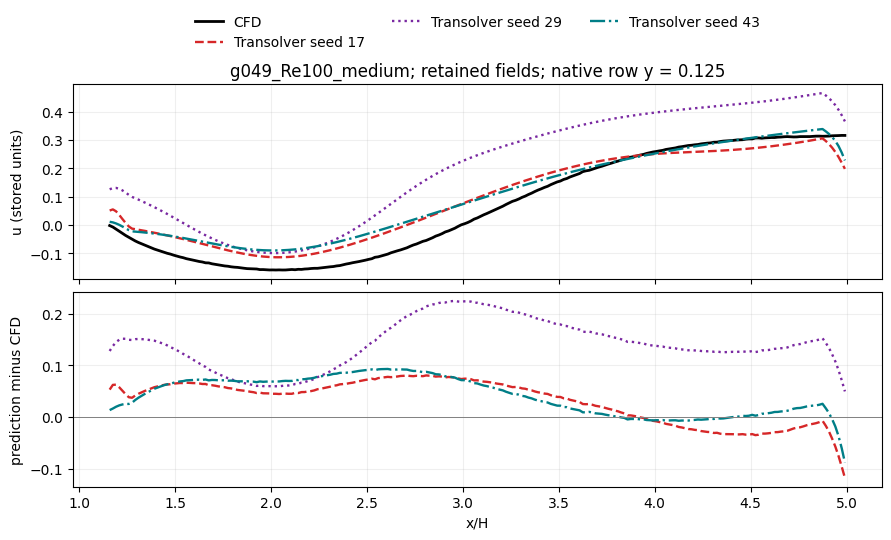

In [5]:
import hashlib
import numpy as np
import matplotlib.pyplot as plt
from flowmllab.late_teaching_plots import field_profiles
CASE = 'g049_Re100_medium'
COMPONENT = "u"  # u, v or pressure; no checkpoint selection
CUT_Y = .12
folder = ROOT / "results/family_transolver"
receipt = json.loads((folder/"verification.json").read_text())
available = sorted({r["case"] for r in receipt["records"]})
print("Retained cases:", available)
if CASE not in available: raise ValueError("Choose a case printed above")
if COMPONENT not in ("u","v","pressure"): raise ValueError("Choose u, v or pressure")
fields=[]
for seed in (17,29,43):
    row=next(r for r in receipt["records"] if r["seed"]==seed and r["case"]==CASE)
    path=folder/f"seed_{seed}"/f"{CASE}_prediction.npz"
    actual=hashlib.sha256(path.read_bytes()).hexdigest()
    if actual!=row["prediction_sha256"]: raise ValueError(f"Changed retained field: {path}")
    with np.load(path,allow_pickle=False) as z: fields.append({k:z[k].copy() for k in z.files})
ref=fields[0]; shape=tuple(map(int,ref["shape"]))
mask=ref["mask"].reshape(shape).astype(bool)
xy=ref["coordinates"].reshape(*shape,2)
channel={"u":0,"v":1,"pressure":2}[COMPONENT]
truth=ref["truth"].reshape(*shape,3)[:,:,channel].astype(float)
predictions={}
for seed,f in zip((17,29,43),fields):
    np.testing.assert_array_equal(f["mask"],ref["mask"])
    np.testing.assert_allclose(f["truth"],ref["truth"],rtol=0,atol=0)
    value=f["prediction"].reshape(*shape,3)[:,:,channel].astype(float)
    if COMPONENT=="pressure":value=value-value[mask].mean()
    predictions[f"Transolver seed {seed}"]=value
if COMPONENT=="pressure":truth=truth-truth[mask].mean()
figures,diagnostics=field_profiles(xy[0,:,0],xy[:,0,1],truth,predictions,
    mask=mask,quantity=f"{COMPONENT} (stored units)",case=f"{CASE}; retained fields",
    cut_y=CUT_Y)
display(pd.DataFrame(diagnostics["metrics"]))
print("Native profile row:",diagnostics["native_profile_y"],"; no checkpoint replay in this cell.")
plt.show()


## A controlled student investigation

1. **Locate a missed feature.** At a fixed geometry/Re and seed, report the native coordinate of the largest signed streamwise-velocity discrepancy, and compare the reverse-flow region with CFD. State whether the main error is strength, location or missing connected regions.
2. **Check repeatability.** Keep that case fixed and compare all three seeds. Report their numerical range, and explain why three runs do not establish a universal architecture ranking.
3. **Change the quantity.** Repeat the same-case comparison for pressure after common fluid-mean centering. Explain why a change in the pressure zero cannot correct the velocity error.
4. **Compare Reynolds regimes.** Use every available Re for the chosen geometry. Submit the matched field/signed-profile figures and a compact table with case, seed, metric definition and native grid. Do not use these retrospective cases to claim a new blind test.

Full checkpoint replay and campaign training are separate research procedures. They require the original dependencies, frozen input/source identities and an isolated output workspace. Default Run All verifies the displayed saved fields and recomputes their diagnostics; it does not rerun those campaigns.